In [1]:
"""
Programa para implementar el algoritmo de descenso de gradiente con
retropropagación
"""
%config InlineBackend.figure_format = 'retina'

import random
import numpy as np
import matplotlib.pyplot as plt
import copy

In [2]:
class Network(object):

    def __init__(self, sizes):
        """The list ``sizes`` contains the number of neurons in the
        respective layers of the network.  For example, if the list
        was [2, 3, 1] then it would be a three-layer network, with the
        first layer containing 2 neurons, the second layer 3 neurons,
        and the third layer 1 neuron.  The biases and weights for the
        network are initialized randomly, using a Gaussian
        distribution with mean 0, and variance 1.  Note that the first
        layer is assumed to be an input layer, and by convention we
        won't set any biases for those neurons, since biases are only
        ever used in computing the outputs from later layers."""
        self.num_layers = len(sizes)
        self.sizes = sizes
        self.biases = [np.random.randn(y, 1) for y in sizes[1:]]
        self.weights = [np.random.randn(y, x)
                        for x, y in zip(sizes[:-1], sizes[1:])]
        self.test_results = []
        self.loss = 0
        self.fallos = 0

    def feedforward(self, a):
        act = a[0:0-1].T
        act = np.array([[a[0],a[1]]]).T
        """Return the output of the network if ``a`` is input."""
        for b, w in zip(self.biases, self.weights):
            act = sigmoid(np.dot(w, act)+b)
        return (act[0][0]>0.5)

    def SGD(self, training_data, epochs, mini_batch_size, lrate,
            test_data=[]):
        """Train the neural network using mini-batch stochastic
        gradient descent.  The ``training_data`` is a list of tuples
        ``(x, y)`` representing the training inputs and the desired
        outputs.  The other non-optional parameters are
        self-explanatory.  If ``test_data`` is provided then the
        network will be evaluated against the test data after each
        epoch, and partial progress printed out.  This is useful for
        tracking progress, but slows things down substantially."""
        if (len(test_data)>0): 
            n_test = len(test_data)
        n = len(training_data)
        print("n",n)
        for j in range(epochs):
            np.random.shuffle(training_data)
            mini_batches = [
                training_data[k:k+mini_batch_size]
                for k in range(0, n, mini_batch_size)]
            for mini_batch in mini_batches:
                self.update_mini_batch(mini_batch, lrate)          
            if len(test_data):
                tasafallos,self.test_results= self.evaluate(test_data)
                tasafallos /= len(test_data)
                print ("Epoch {0} loss {1} Tasa fallos {2}".format(j,self.loss,tasafallos))

            else:
                print ("Epoch {0} complete. loss {1}".format(j,self.loss))
        return 

    def update_mini_batch(self, mini_batch, lrate):
        """Update the network's weights and biases by applying
        gradient descent using backpropagation to a single mini batch.
        The ``mini_batch`` is a list of tuples ``(x, y)``, and ``lrate``
        is the learning rate."""
        nabla_b = [np.zeros(b.shape) for b in self.biases]
        nabla_w = [np.zeros(w.shape) for w in self.weights]
        epoch_loss = 0
        lbatch = len(mini_batch)    
        #for x, y in mini_batch:
        for k in range(lbatch):
            x = np.array([[mini_batch[k][0],mini_batch[k][1]]]).T
            y = mini_batch[k][2]
            delta_nabla_b, delta_nabla_w ,loss = self.backprop(x, y)
            nabla_b = [nb+dnb for nb, dnb in zip(nabla_b, delta_nabla_b)]
            nabla_w = [nw+dnw for nw, dnw in zip(nabla_w, delta_nabla_w)]
            epoch_loss += loss
        self.weights = [w-(lrate/lbatch)*nw
                        for w, nw in zip(self.weights, nabla_w)]
        self.biases = [b-(lrate/lbatch)*nb
                       for b, nb in zip(self.biases, nabla_b)]
        self.loss = epoch_loss/lbatch

    def backprop(self, x, y):
        """Return a tuple ``(nabla_b, nabla_w)`` representing the
        gradient for the loss function C_x.  ``nabla_b`` and
        ``nabla_w`` are layer-by-layer lists of numpy arrays, similar
        to ``self.biases`` and ``self.weights``."""
        nabla_b = [np.zeros(b.shape) for b in self.biases]
        nabla_w = [np.zeros(w.shape) for w in self.weights]
        # feedforward
        activation = x
        activations = [x] # list to store all the activations, layer by layer
        zs = [] # list to store all the z vectors, layer by layer
        for b, w in zip(self.biases, self.weights):
            z = np.dot(w, activation)+b
            zs.append(z)
            activation = sigmoid(z)
            activations.append(activation)
        # backward pass
        loss = (0.5)*(activations[-1]-y)**2
        delta = self.loss_derivative(activations[-1], y) * \
            sigmoid_prime(zs[-1])
        nabla_b[-1] = delta
        nabla_w[-1] = np.dot(delta, activations[-2].transpose())
        # Note that the variable l in the loop below is used a little
        # differently to the notation in Chapter 2 of the book.  Here,
        # l = 1 means the last layer of neurons, l = 2 is the
        # second-last layer, and so on.  It's a renumbering of the
        # scheme in the book, used here to take advantage of the fact
        # that Python can use negative indices in lists.
        for l in range(2, self.num_layers):
            z = zs[-l]
            sp = sigmoid_prime(z)
            delta = np.dot(self.weights[-l+1].transpose(), delta) * sp
            nabla_b[-l] = delta
            nabla_w[-l] = np.dot(delta, activations[-l-1].transpose())
        return (nabla_b, nabla_w, loss)

    def evaluate(self, test_data):
        """Return the number of test inputs for which the neural
        network outputs the correct result. Note that the neural
        network's output is assumed to be the index of whichever
        neuron in the final layer has the highest activation."""
        test_labels = [test_data[k][2] for k in range(len(test_data))]
        self.test_results = [self.feedforward(x) for x in test_data]
        self.fallos = np.sum(abs(np.array(test_labels)-np.array(self.test_results))) 
        return self.fallos, np.array(self.test_results)*1.0

    def loss_derivative(self, output_activations, y):
        """Return the vector of partial derivatives C_x for the output activations."""
        return (output_activations-y)

In [3]:
#### Miscellaneous functions
def sigmoid(z):
    """The sigmoid function."""
    return 1.0/(1.0+np.exp(-z))

def sigmoid_prime(z):
    """Derivative of the sigmoid function."""
    return sigmoid(z)*(1-sigmoid(z))


# Crea un array de números aletorios con distribución normal de media cero y desviación estándar 1
def random_init(longitud):
    return (np.random.randn(longitud))

# Crea los datos de entrada. 
def crea_datos(numpuntos):
    inputs = [np.array(np.random.rand(numpuntos))]  # Fila 0, valores x
    inputs.append(np.random.rand(numpuntos))        # Fila 1, valores y   
    inputs.append(np.zeros(numpuntos))              # Fila 2, etiquetas
    for i in range(numpuntos):
        #inputs[2][i] = ((inputs[1][i]**2+inputs[0][i]**2)<0.5) or (inputs[0][i]>0.9)
        inputs[2][i] = ((inputs[1][i]**2+inputs[0][i]**2)<0.33) or (((inputs[1][i]-1)**2+(inputs[0][i]-1)**2)<0.33)
        #inputs[2][i] = ((inputs[1][i]+inputs[0][i])<1)
    datos = [[inputs[0][i],inputs[1][i],inputs[2][i]] for i in range(numpuntos)]
    datos = np.array(datos).reshape(numpuntos,3)
    return datos

In [4]:
def plot_data(data,plabels=""):
    fig = plt.figure(figsize=(5,5))
    ax = fig.add_subplot(111)
    cols=["blue","green","red"]
    for v in range(3):
        dplot = data[data[:,2]==v]
        if len(plabels)==0:
            pass
        else:
            dplot = data[plabels==v]
        ax.scatter(dplot[:,0], dplot[:,1], color=cols[v], s=10,  zorder=50)
    nudge = 0.02
    ax.set_aspect('equal', 'datalim')
    plt.show()
    return

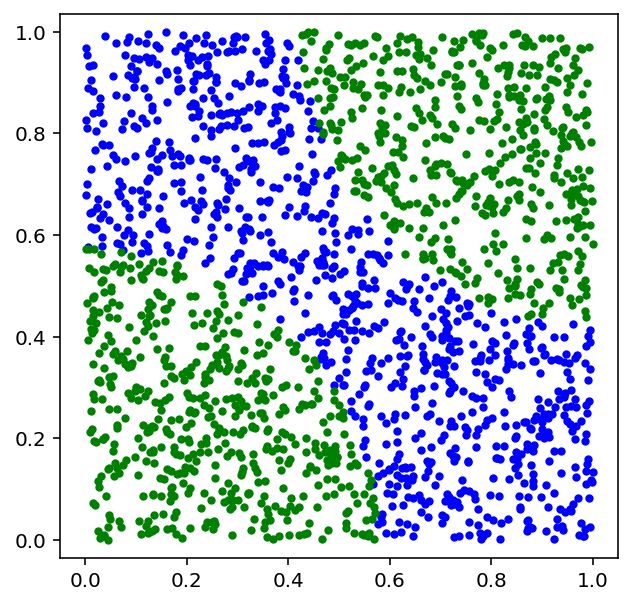

In [5]:
NUM_PUNTOS_ALL = 10000
NUM_PUNTOS_TRAIN = round(0.8*NUM_PUNTOS_ALL)
NUM_PUNTOS_TEST = NUM_PUNTOS_ALL - NUM_PUNTOS_TRAIN
numpuntosplot=2000
np.random.seed(2025)
train_samples = crea_datos(NUM_PUNTOS_TRAIN)
plot_data(train_samples[0:numpuntosplot])

In [6]:
test_samples = crea_datos(NUM_PUNTOS_TEST)
net = Network ([2, 20, 10, 4, 1])
#net = Network ([2, 3, 1])

nepochs = 40 #round(NUM_PUNTOS_TRAIN/batch_size)
batch_size = 10
learning_rate = 0.3
net.SGD(train_samples , nepochs, batch_size, learning_rate, test_data=test_samples)

n 8000
Epoch 0 loss [[0.12516255]] Tasa fallos 0.468
Epoch 1 loss [[0.12562487]] Tasa fallos 0.4065
Epoch 2 loss [[0.12671377]] Tasa fallos 0.468
Epoch 3 loss [[0.12564189]] Tasa fallos 0.468
Epoch 4 loss [[0.11909092]] Tasa fallos 0.532
Epoch 5 loss [[0.12208814]] Tasa fallos 0.468
Epoch 6 loss [[0.12483101]] Tasa fallos 0.434
Epoch 7 loss [[0.12532851]] Tasa fallos 0.6045
Epoch 8 loss [[0.12348567]] Tasa fallos 0.468
Epoch 9 loss [[0.12431028]] Tasa fallos 0.557
Epoch 10 loss [[0.1348619]] Tasa fallos 0.468
Epoch 11 loss [[0.11654142]] Tasa fallos 0.468
Epoch 12 loss [[0.12469774]] Tasa fallos 0.369
Epoch 13 loss [[0.12161824]] Tasa fallos 0.36
Epoch 14 loss [[0.10586943]] Tasa fallos 0.313
Epoch 15 loss [[0.10537626]] Tasa fallos 0.213
Epoch 16 loss [[0.07894134]] Tasa fallos 0.1865
Epoch 17 loss [[0.05299212]] Tasa fallos 0.152
Epoch 18 loss [[0.05244907]] Tasa fallos 0.072
Epoch 19 loss [[0.03717043]] Tasa fallos 0.0325
Epoch 20 loss [[0.05881235]] Tasa fallos 0.033
Epoch 21 loss 

In [7]:
aciertos = NUM_PUNTOS_TEST-net.fallos
tasa_test=(aciertos/NUM_PUNTOS_TEST)
print(aciertos,NUM_PUNTOS_TEST)
print("tasa test",tasa_test)

1966.0 2000
tasa test 0.983


In [8]:
fallos, test_results = net.evaluate(test_samples)
npunt = min(numpuntosplot,NUM_PUNTOS_TEST)
labels=1.0*np.array(test_results)[0:npunt]
test_labels = np.array([test_samples[k][2] for k in range(npunt)])
for i in range(npunt):
    if (labels[i] != test_labels[i]):
        labels[i] = 2

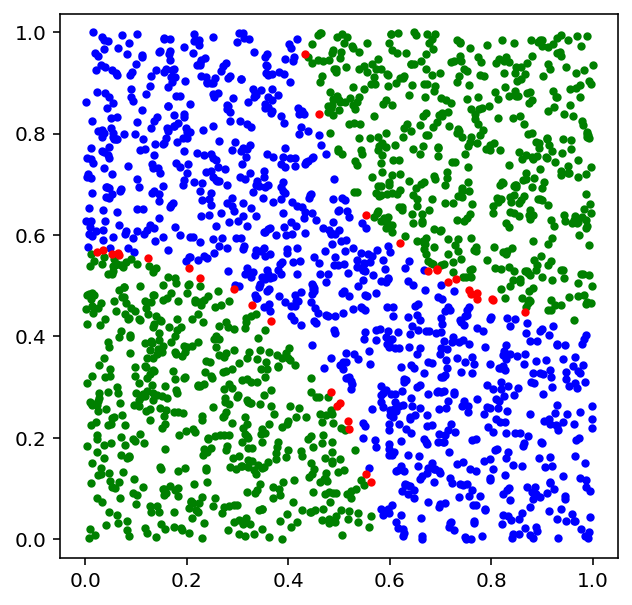

In [9]:
plot_data(test_samples[0:npunt],plabels=labels)